# Phase 3a - Zero-Shot RF-DETR Baseline Comparison


## 1. Install and verify


In [1]:
!pip install -q "rfdetr[train,loggers]" supervision pycocotools

import torch
from rfdetr import RFDETRSmall
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU  :", torch.cuda.get_device_name(0))
print("\nSection 1 OK.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.3/373.3 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.5/35.5 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 94.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Configuration and the COCO → ExDark class map

All twelve ExDark classes exist in COCO-80. Three need renaming (`People→person`,
`Motorbike→motorcycle`, `Table→dining table`); the rest match directly. Only these twelve COCO classes
are scored — every other COCO prediction is discarded rather than counted as a false positive, which
keeps the comparison fair to the zero-shot model.


In [2]:
import os, json, glob, time

RUN_TAG = "yoloworld_v8"
DRIVE_ROOT   = "/content/drive/MyDrive/ExDark_dataset"
P1_MANIFEST  = f"{DRIVE_ROOT}/phase1_outputs_{RUN_TAG}/phase1_manifest.json"
P2_RESULTS   = f"{DRIVE_ROOT}/phase2_results_{RUN_TAG}/phase2_results.json"
P2B_RESULTS  = f"{DRIVE_ROOT}/phase2b_results_{RUN_TAG}/phase2b_results.json"
P2_WORK      = "/content/phase2_datasets"     # reuse Phase 2's unzipped A/B if still present
WORK_ROOT    = "/content/supp_datasets"
RESULTS_DIR  = f"{DRIVE_ROOT}/supplementary_zeroshot_{RUN_TAG}"

EVAL_CONF      = 0.01     # low, so the PR curve is complete for COCOeval
MAX_DETECTIONS = 100
IOU_MATCH      = 0.50

EXDARK_CLASSES = ["Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
                  "Chair", "Cup", "Dog", "Motorbike", "People", "Table"]

# ExDark class -> COCO-80 class name
EXDARK_TO_COCO = {
    "Bicycle": "bicycle", "Boat": "boat", "Bottle": "bottle", "Bus": "bus",
    "Car": "car", "Cat": "cat", "Chair": "chair", "Cup": "cup", "Dog": "dog",
    "Motorbike": "motorcycle", "People": "person", "Table": "dining table",
}
COCO_TO_EXDARK = {v: k for k, v in EXDARK_TO_COCO.items()}

COCO80 = ['person','bicycle','car','motorcycle','airplane','bus','train','truck','boat',
 'traffic light','fire hydrant','stop sign','parking meter','bench','bird','cat','dog','horse',
 'sheep','cow','elephant','bear','zebra','giraffe','backpack','umbrella','handbag','tie','suitcase',
 'frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove','skateboard',
 'surfboard','tennis racket','bottle','wine glass','cup','fork','knife','spoon','bowl','banana',
 'apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut','cake','chair','couch',
 'potted plant','bed','dining table','toilet','tv','laptop','mouse','remote','keyboard','cell phone',
 'microwave','oven','toaster','sink','refrigerator','book','clock','vase','scissors','teddy bear',
 'hair drier','toothbrush']

print("Class mapping (all 12 present in COCO-80):")
for k, v in EXDARK_TO_COCO.items():
    print(f"  {k:<10} -> {v:<14} (COCO idx {COCO80.index(v)})")


Class mapping (all 12 present in COCO-80):
  Bicycle    -> bicycle        (COCO idx 1)
  Boat       -> boat           (COCO idx 8)
  Bottle     -> bottle         (COCO idx 39)
  Bus        -> bus            (COCO idx 5)
  Car        -> car            (COCO idx 2)
  Cat        -> cat            (COCO idx 15)
  Chair      -> chair          (COCO idx 56)
  Cup        -> cup            (COCO idx 41)
  Dog        -> dog            (COCO idx 16)
  Motorbike  -> motorcycle     (COCO idx 3)
  People     -> person         (COCO idx 0)
  Table      -> dining table   (COCO idx 60)


## 3. Mount Drive & locate the test splits

Condition A supplies the raw test images, Condition B the enhanced ones. Both carry identical human
ground truth, so any difference is attributable to the images alone.


In [3]:
from google.colab import drive
import zipfile, shutil

def robust_mount(mp="/content/drive", tries=3):
    for i in range(tries):
        try:
            drive.mount(mp, force_remount=True); return
        except ValueError as e:
            print(f"[mount] attempt {i+1} failed: {e}")
            os.system(f"fusermount -u {mp} 2>/dev/null"); os.system(f"rm -rf {mp}")
            time.sleep(3)
    drive.mount(mp)

robust_mount()

M = json.load(open(P1_MANIFEST))
print("[phase1] manifest loaded")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(WORK_ROOT, exist_ok=True)

def get_dataset(name):
    for root in (P2_WORK, WORK_ROOT):
        d = os.path.join(root, name)
        if os.path.isfile(os.path.join(d, "test", "_annotations.coco.json")):
            print(f"[data] {name}: reusing {d}"); return d
    zpath = (M.get("persisted_zips", {}) or {}).get(name) or \
            os.path.join(M["dataset_zip_dir"], name + ".zip")
    if not os.path.isfile(zpath):
        raise FileNotFoundError(f"{name}: zip not found ({zpath})")
    dest = os.path.join(WORK_ROOT, name)
    print(f"[data] unzipping {name} ..."); t = time.time()
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zpath) as z: z.extractall(dest)
    print(f"[data]   done in {time.time()-t:.0f}s")
    return dest

DS = {"raw": get_dataset("A_raw_human"), "enhanced": get_dataset("B_enh_human")}
for k, v in DS.items():
    c = json.load(open(os.path.join(v, "test", "_annotations.coco.json")))
    print(f"{k:<9}: {len(c['images'])} test images, {len(c['annotations'])} GT boxes")


Mounted at /content/drive
[phase1] manifest loaded
[data] unzipping A_raw_human ...
[data]   done in 29s
[data] unzipping B_enh_human ...
[data]   done in 128s
raw      : 748 test images, 2218 GT boxes
enhanced : 748 test images, 2218 GT boxes


## 4. Load the COCO-pretrained model

`RFDETRSmall()` with no checkpoint argument loads the same COCO weights every fine-tuned condition
started from. The class-name list is read off the model where available, so the COCO id mapping is
resolved from the model itself rather than assumed.


In [4]:
model = RFDETRSmall()

names = getattr(model, "class_names", None)
if names:
    print(f"Model exposes {len(names)} class names; first 5: {list(names)[:5]}")
    NAME_LOOKUP = {i: str(n).lower() for i, n in enumerate(names)}
else:
    print("[warn] model.class_names unavailable — falling back to the standard COCO-80 ordering.")
    NAME_LOOKUP = {i: n for i, n in enumerate(COCO80)}

# which model class indices correspond to our twelve ExDark classes
KEEP_IDX = {i: COCO_TO_EXDARK[n] for i, n in NAME_LOOKUP.items() if n in COCO_TO_EXDARK}
print(f"\nMapped {len(KEEP_IDX)}/12 ExDark classes from the model's label space:")
for i, c in sorted(KEEP_IDX.items()): print(f"  idx {i:>3} -> {c}")
missing = set(EXDARK_CLASSES) - set(KEEP_IDX.values())
if missing:
    print(f"\n[WARN] unmapped: {missing} — these will score 0 AP for the wrong reason. "
          "Check the model's label space before interpreting.")


[2026-08-11 06:31:15] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-small.pth


/root/.roboflow/models/rf-detr-small.pth:   0%|          | 0.00/368M [00:00<?, ?iB/s]

[2026-08-11 06:31:26] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-small.pth


[2026-08-11 06:31:26] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-08-11 06:31:26] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-08-11 06:31:29] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-08-11 06:31:31] [WARNING] rf-detr - Pretrained weights at '/root/.roboflow/models/rf-detr-small.pth' loaded only partially — this typically produces lower accuracy. 1 model parameter(s) not in checkpoint (left at random init): [_kp_active_mask]. Check that the model configuration (encoder, hidden_dim, out_feature_indexes, projector_scale, ...) matches the architecture the checkpoint was trained with.


Model exposes 80 class names; first 5: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']

Mapped 12/12 ExDark classes from the model's label space:
  idx   0 -> People
  idx   1 -> Bicycle
  idx   2 -> Car
  idx   3 -> Motorbike
  idx   5 -> Bus
  idx   8 -> Boat
  idx  15 -> Cat
  idx  16 -> Dog
  idx  39 -> Bottle
  idx  41 -> Cup
  idx  56 -> Chair
  idx  60 -> Table


## 5. Zero-shot evaluation

Identical protocol to Phases 2 and 2b: COCOeval with `maxDets=[1,10,100]` on the shared test split,
plus a per-detection dump with matched-GT IoU so the box-geometry comparison carries over.


In [5]:
import numpy as np, pandas as pd
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io as _io

def resolve_cls(cid, cname=None):
    """Map a model prediction to an ExDark class, or None if outside the 12.
    Prefers the model's own class_name; falls back to 0-based then 1-based COCO ids."""
    if isinstance(cname, str):
        return COCO_TO_EXDARK.get(cname.lower().strip())
    i = int(cid)
    nm = NAME_LOOKUP.get(i)                    # 0-based
    if nm in COCO_TO_EXDARK:
        return COCO_TO_EXDARK[nm]
    nm = NAME_LOOKUP.get(i - 1)                # 1-based COCO category id
    return COCO_TO_EXDARK.get(nm) if nm else None

def _iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
    ua = max(0.0, a[2]-a[0]) * max(0.0, a[3]-a[1])
    ub = max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])
    d = ua + ub - inter
    return inter / d if d > 0 else 0.0

def _area(b): return max(0.0, b[2]-b[0]) * max(0.0, b[3]-b[1])

def evaluate_zeroshot(tag, dataset_dir):
    test_dir = os.path.join(dataset_dir, "test")
    coco_gt = COCO(os.path.join(test_dir, "_annotations.coco.json"))
    cats = coco_gt.loadCats(coco_gt.getCatIds())
    name_to_catid = {c["name"]: c["id"] for c in cats if c["name"] != "exdark"}
    id_to_name = {c["id"]: c["name"] for c in cats}
    fname_to_id = {coco_gt.loadImgs(i)[0]["file_name"]: i for i in coco_gt.getImgIds()}

    results, records, n_dropped = [], [], 0
    for fn, img_id in fname_to_id.items():
        p = os.path.join(test_dir, fn)
        if not os.path.isfile(p): continue
        det = model.predict(Image.open(p).convert("RGB"), threshold=EVAL_CONF)
        xyxy = getattr(det, "xyxy", None); conf = getattr(det, "confidence", None)
        cid  = getattr(det, "class_id", None); data = getattr(det, "data", {}) or {}
        cnames = data.get("class_name") if isinstance(data, dict) else None
        n = 0 if xyxy is None else len(xyxy)
        order = np.argsort(-conf) if (conf is not None and n) else range(n)

        gts = [{"id": a["id"], "cat": a["category_id"],
                "box": [a["bbox"][0], a["bbox"][1],
                        a["bbox"][0]+a["bbox"][2], a["bbox"][1]+a["bbox"][3]]}
               for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id))]
        claimed, kept = set(), 0
        for k in order:
            cname = cnames[k] if cnames is not None else None
            cls = resolve_cls(cid[k], cname)
            if cls is None:          # a COCO class outside the 12 -> not scored
                n_dropped += 1; continue
            if kept >= MAX_DETECTIONS: break
            kept += 1
            x1, y1, x2, y2 = [float(v) for v in xyxy[k]]
            catid = name_to_catid[cls]; score = float(conf[k])
            results.append({"image_id": int(img_id), "category_id": int(catid),
                            "bbox": [x1, y1, x2-x1, y2-y1], "score": score})
            bi, bg = 0.0, None
            for g in gts:
                if g["cat"] != catid or g["id"] in claimed: continue
                v = _iou_xyxy([x1, y1, x2, y2], g["box"])
                if v > bi: bi, bg = v, g["id"]
            tp = bi >= IOU_MATCH and bg is not None
            if tp: claimed.add(bg)
            records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                            "kind": "detection", "cls": cls, "score": score,
                            "best_iou": bi, "tp": bool(tp), "gt_id": bg if tp else None,
                            "x1": x1, "y1": y1, "x2": x2, "y2": y2})
        for g in gts:
            if g["id"] not in claimed:
                records.append({"run": tag, "image_id": int(img_id), "file_name": fn,
                                "kind": "missed_gt", "cls": id_to_name.get(g["cat"]),
                                "score": np.nan, "best_iou": np.nan, "tp": False,
                                "gt_id": g["id"], "x1": g["box"][0], "y1": g["box"][1],
                                "x2": g["box"][2], "y2": g["box"][3]})

    coco_dt = coco_gt.loadRes(results)
    ev = COCOeval(coco_gt, coco_dt, "bbox"); ev.params.maxDets = [1, 10, 100]
    with contextlib.redirect_stdout(_io.StringIO()):
        ev.evaluate(); ev.accumulate(); ev.summarize()
    prec = ev.eval["precision"]; idx50 = int(np.argmin(np.abs(ev.params.iouThrs - 0.5)))
    per, per50, ap_all, ap50_all = {}, {}, [], []
    for k, cid_ in enumerate(coco_gt.getCatIds()):
        nm = id_to_name.get(cid_)
        if nm == "exdark": continue
        pr = prec[:, :, k, 0, -1]; pr = pr[pr > -1]
        ap = float(pr.mean()) if pr.size else float("nan")
        pr5 = prec[idx50, :, k, 0, -1]; pr5 = pr5[pr5 > -1]
        ap5 = float(pr5.mean()) if pr5.size else float("nan")
        per[nm], per50[nm] = round(ap, 4), round(ap5, 4)
        if not np.isnan(ap): ap_all.append(ap)
        if not np.isnan(ap5): ap50_all.append(ap5)
    metrics = {"mAP": round(float(np.mean(ap_all)), 4) if ap_all else None,
               "mAP50": round(float(np.mean(ap50_all)), 4) if ap50_all else None,
               "per_class": per, "per_class_50": per50}
    df = pd.DataFrame(records)
    df.to_parquet(os.path.join(RESULTS_DIR, f"detections_zeroshot_{tag}.parquet"), index=False)
    n_tp = int(df[(df.kind == "detection")].tp.sum())
    print(f"[eval] zero-shot / {tag}: mAP@0.5={metrics['mAP50']}  mAP@[.5:.95]={metrics['mAP']}  "
          f"| {n_tp} TP, {n_dropped} non-ExDark detections discarded")
    return {"metrics": metrics, "records": df}

ZS = {}
for cond, d in DS.items():
    ZS[f"ZeroShot@{cond}"] = evaluate_zeroshot(cond, d)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


[2026-08-11 06:31:32] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.36s)
creating index...
index created!
[eval] zero-shot / raw: mAP@0.5=0.7315  mAP@[.5:.95]=0.402  | 2040 TP, 69207 non-ExDark detections discarded
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.50s)
creating index...
index created!
[eval] zero-shot / enhanced: mAP@0.5=0.7291  mAP@[.5:.95]=0.4016  | 2026 TP, 76173 non-ExDark detections discarded


## 6. Plotting helpers

Same convention as Phases 2 and 2b: `pad_for_break` after plotting, then `mark_axis_break`.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

def mark_axis_break(ax, x=None, y=None, size=0.012, gap=0.010, pos=0.045, lw=1.2):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    if x is None: x = xlim[0] > 1e-9
    if y is None: y = ylim[0] > 1e-9
    kw = dict(transform=ax.transAxes, color="black", clip_on=False,
              linewidth=lw, solid_capstyle="butt", zorder=10)
    if x:
        for off in (-gap/2, gap/2):
            ax.plot([pos+off-size, pos+off+size], [-size, size], **kw)
    if y:
        for off in (-gap/2, gap/2):
            ax.plot([-size, size], [pos+off-size, pos+off+size], **kw)
    return ax

def pad_for_break(ax, frac=0.10, x=True, y=True):
    if x:
        x0, x1 = ax.get_xlim(); ax.set_xlim(x0 - frac*(x1-x0), x1)
    if y:
        y0, y1 = ax.get_ylim(); ax.set_ylim(y0 - frac*(y1-y0), y1)
    return ax

def savefig(fig, name):
    fig.savefig(os.path.join(RESULTS_DIR, name), dpi=130, bbox_inches="tight")


## 7. The baseline in context

Places the zero-shot floor alongside every trained condition. **Adaptation gain** is the mAP a condition
adds over the zero-shot baseline on the same image type — the portion genuinely attributable to ExDark
training rather than inherited COCO capability.


=== All conditions vs the zero-shot floor ===


,Run,images,trained,mAP@0.5,mAP@[.5:.95],adaptation_gain,gain@0.5,pct_above_zeroshot,pct_of_headroom
0,A,raw,yes,0.8931,0.6339,0.2319,0.1616,57.7,105.8
1,B,enhanced,yes,0.8829,0.6208,0.2192,0.1538,54.6,100.0
2,H25,enhanced,yes,0.8267,0.4794,0.0778,0.0976,19.4,35.5
3,H10,enhanced,yes,0.7993,0.4494,0.0478,0.0702,11.9,21.8
4,C@0.55,enhanced,yes,0.7581,0.4203,0.0187,0.0290,4.7,8.5
5,C@0.60,enhanced,yes,0.7551,0.4164,0.0148,0.0260,3.7,6.8
6,ZeroShot (raw),raw,no,0.7315,0.4020,0.0000,0.0000,0.0,0.0
7,ZeroShot (enhanced),enhanced,no,0.7291,0.4016,0.0000,0.0000,0.0,0.0



Zero-shot floor: raw 0.7315 / 0.4020   enhanced 0.7291 / 0.4016  (mAP@0.5 / mAP@[.5:.95])
Enhancement effect, zero-shot: -0.0004 mAP@[.5:.95] (-0.0024 @0.5)
Adaptation headroom (B - enhanced floor): 0.2192 mAP@[.5:.95]


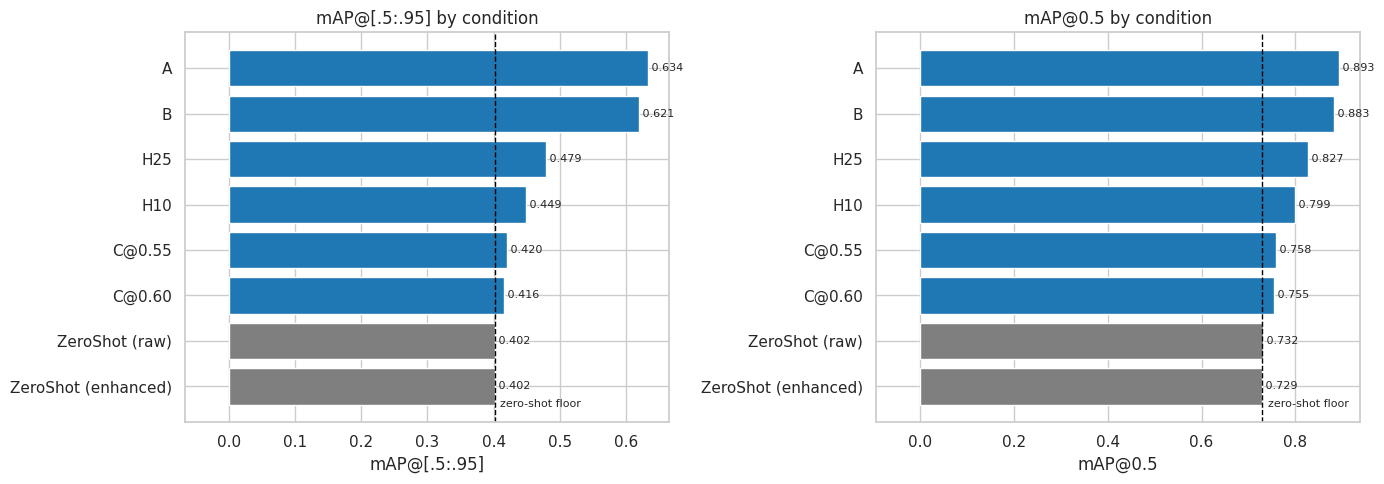

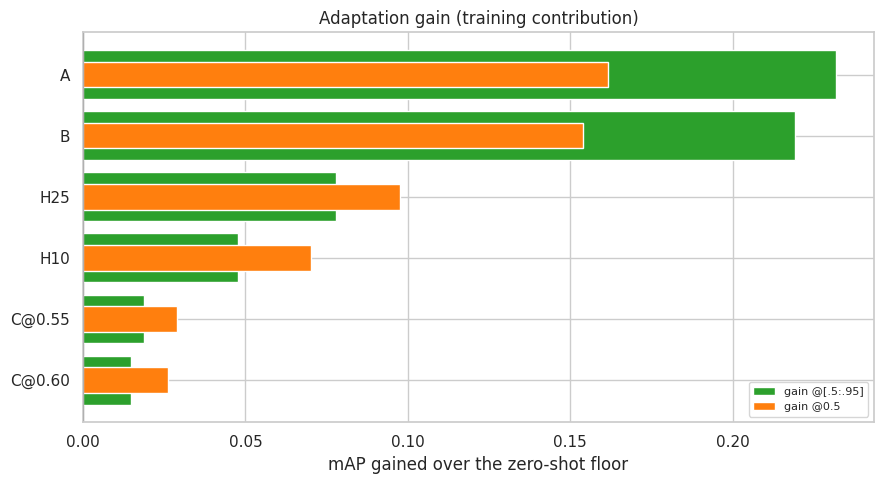

In [7]:
P2  = json.load(open(P2_RESULTS))  if os.path.isfile(P2_RESULTS)  else None
P2B = json.load(open(P2B_RESULTS)) if os.path.isfile(P2B_RESULTS) else None

# Which image pool each trained condition used. Everything not listed is enhanced,
# so each condition is scored against the floor for its own image type.
COND_IMAGES = {"A": "raw"}
def images_of(tag): return COND_IMAGES.get(tag, "enhanced")

rows = []
for cond in ("raw", "enhanced"):
    m = ZS[f"ZeroShot@{cond}"]["metrics"]
    rows.append({"Run": f"ZeroShot ({cond})", "images": cond, "trained": "no",
                 "mAP@0.5": m["mAP50"], "mAP@[.5:.95]": m["mAP"]})
if P2:
    for tag in ("A", "B", "C@0.55", "C@0.60"):
        m = (P2.get("results", {}).get(tag) or {}).get("metrics")
        if m:
            rows.append({"Run": tag, "images": images_of(tag), "trained": "yes",
                         "mAP@0.5": m["mAP50"], "mAP@[.5:.95]": m["mAP"]})
if P2B:
    for tag, m in (P2B.get("results") or {}).items():
        rows.append({"Run": tag, "images": images_of(tag), "trained": "yes",
                     "mAP@0.5": m["mAP50"], "mAP@[.5:.95]": m["mAP"]})

ALL = pd.DataFrame(rows)
FLOOR   = {c: ALL.loc[ALL.Run == f"ZeroShot ({c})", "mAP@[.5:.95]"].iloc[0] for c in ("raw", "enhanced")}
FLOOR50 = {c: ALL.loc[ALL.Run == f"ZeroShot ({c})", "mAP@0.5"].iloc[0]      for c in ("raw", "enhanced")}

ALL["baseline"]           = ALL["images"].map(FLOOR)
ALL["baseline@0.5"]       = ALL["images"].map(FLOOR50)
ALL["adaptation_gain"]    = (ALL["mAP@[.5:.95]"] - ALL["baseline"]).round(4)
ALL["gain@0.5"]           = (ALL["mAP@0.5"]      - ALL["baseline@0.5"]).round(4)
ALL["pct_above_zeroshot"] = (100 * ALL["adaptation_gain"] / ALL["baseline"]).round(1)

# Headroom = what full human supervision on enhanced images achieves.
HEADROOM = float(ALL.loc[ALL.Run == "B", "adaptation_gain"].iloc[0]) if (ALL.Run == "B").any() else None
if HEADROOM:
    ALL["pct_of_headroom"] = (100 * ALL["adaptation_gain"] / HEADROOM).round(1)

ALL = ALL.sort_values("mAP@[.5:.95]", ascending=False).reset_index(drop=True)

print("=== All conditions vs the zero-shot floor ===")
_show = ["Run", "images", "trained", "mAP@0.5", "mAP@[.5:.95]",
         "adaptation_gain", "gain@0.5", "pct_above_zeroshot"]
if HEADROOM: _show.append("pct_of_headroom")
display(ALL[_show])

print(f"\nZero-shot floor: raw {FLOOR50['raw']:.4f} / {FLOOR['raw']:.4f}   "
      f"enhanced {FLOOR50['enhanced']:.4f} / {FLOOR['enhanced']:.4f}  (mAP@0.5 / mAP@[.5:.95])")
print(f"Enhancement effect, zero-shot: {FLOOR['enhanced'] - FLOOR['raw']:+.4f} mAP@[.5:.95] "
      f"({FLOOR50['enhanced'] - FLOOR50['raw']:+.4f} @0.5)")
if HEADROOM: print(f"Adaptation headroom (B - enhanced floor): {HEADROOM:.4f} mAP@[.5:.95]")

# Panel per metric: absolute score, with the floor for that metric marked.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, floors in ((axes[0], "mAP@[.5:.95]", FLOOR), (axes[1], "mAP@0.5", FLOOR50)):
    _p = ALL.sort_values(metric)
    ax.barh(_p.Run, _p[metric],
            color=["tab:grey" if t == "no" else "tab:blue" for t in _p.trained])
    ax.axvline(floors["enhanced"], ls="--", color="black", lw=1)
    for y, v in enumerate(_p[metric]):
        ax.text(v, y, f" {v:.3f}", va="center", fontsize=8)
    ax.set_xlabel(metric); ax.set_title(f"{metric} by condition")
    ax.annotate("zero-shot floor", (floors["enhanced"], -0.45), fontsize=8,
                textcoords="offset points", xytext=(4, 0))
    pad_for_break(ax, y=False); mark_axis_break(ax)
plt.tight_layout(); savefig(fig, "zeroshot_context.png"); plt.show()

# Gain over the floor, both metrics, trained conditions only.
fig, ax = plt.subplots(figsize=(9, 5))
_t = ALL[ALL.trained == "yes"].sort_values("adaptation_gain")
ax.barh(_t.Run, _t.adaptation_gain, color="tab:green", label="gain @[.5:.95]")
ax.barh(_t.Run, _t["gain@0.5"], height=0.42, color="tab:orange", label="gain @0.5")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("mAP gained over the zero-shot floor")
ax.set_title("Adaptation gain (training contribution)")
ax.legend(fontsize=8)
plt.tight_layout(); savefig(fig, "zeroshot_gain.png"); plt.show()

## 8. Per-class — where COCO pretraining already suffices

Classes whose zero-shot AP is already close to the trained conditions gained little from ExDark
training; classes near zero zero-shot are where the pipeline does real work. This distinguishes
"the pipeline learned this" from "COCO already knew it."


=== Per-class AP@[.5:.95]: zero-shot vs trained ===


,ZeroShot (raw),ZeroShot (enhanced),A,B,C@0.55,C@0.60,H10,H25,gain_A,gain_B,gain_C@0.55,gain_C@0.60,gain_H10,gain_H25
Bus,0.646,0.654,0.784,0.796,0.650,0.642,0.658,0.686,0.138,0.142,-0.004,-0.012,0.003,0.032
Motorbike,0.513,0.500,0.670,0.662,0.514,0.516,0.550,0.568,0.156,0.162,0.015,0.016,0.050,0.068
Car,0.472,0.476,0.640,0.627,0.482,0.490,0.507,0.530,0.168,0.150,0.006,0.014,0.031,0.054
People,0.441,0.452,0.584,0.590,0.435,0.433,0.452,0.471,0.143,0.138,-0.016,-0.018,0.000,0.019
Cat,0.499,0.445,0.636,0.623,0.444,0.438,0.458,0.483,0.137,0.178,-0.000,-0.007,0.013,0.038
Dog,0.426,0.425,0.717,0.686,0.416,0.420,0.451,0.454,0.291,0.261,-0.009,-0.006,0.026,0.029
Chair,0.354,0.370,0.605,0.583,0.424,0.430,0.437,0.486,0.251,0.213,0.054,0.061,0.067,0.116
Bicycle,0.359,0.366,0.608,0.590,0.443,0.438,0.448,0.502,0.249,0.224,0.077,0.072,0.081,0.136
Cup,0.328,0.341,0.628,0.612,0.377,0.376,0.401,0.438,0.300,0.270,0.036,0.034,0.060,0.097
Bottle,0.324,0.303,0.624,0.600,0.319,0.319,0.341,0.356,0.300,0.297,0.016,0.016,0.038,0.053


=== Per-class AP@0.5: zero-shot vs trained ===


,ZeroShot (raw),ZeroShot (enhanced),A,B,C@0.55,C@0.60,H10,H25,gain_A,gain_B,gain_C@0.55,gain_C@0.60,gain_H10,gain_H25
Bus,0.927,0.930,0.940,0.943,0.929,0.933,0.927,0.946,0.014,0.012,-0.001,0.003,-0.003,0.016
Motorbike,0.852,0.874,0.927,0.910,0.843,0.845,0.887,0.888,0.075,0.036,-0.031,-0.029,0.014,0.014
Car,0.819,0.817,0.910,0.896,0.815,0.817,0.844,0.857,0.091,0.078,-0.002,-0.000,0.027,0.040
People,0.818,0.816,0.897,0.902,0.803,0.807,0.823,0.843,0.079,0.086,-0.014,-0.009,0.006,0.027
Cat,0.834,0.783,0.918,0.926,0.776,0.798,0.817,0.848,0.085,0.143,-0.008,0.014,0.034,0.065
Dog,0.816,0.818,0.931,0.921,0.851,0.843,0.854,0.873,0.116,0.103,0.033,0.025,0.036,0.055
Chair,0.655,0.678,0.876,0.848,0.760,0.758,0.784,0.810,0.220,0.170,0.082,0.080,0.106,0.132
Bicycle,0.720,0.681,0.877,0.878,0.819,0.780,0.820,0.874,0.157,0.198,0.138,0.100,0.139,0.193
Cup,0.649,0.666,0.878,0.866,0.732,0.736,0.758,0.786,0.229,0.200,0.066,0.070,0.091,0.120
Bottle,0.698,0.690,0.889,0.868,0.725,0.703,0.761,0.770,0.191,0.178,0.034,0.013,0.070,0.080


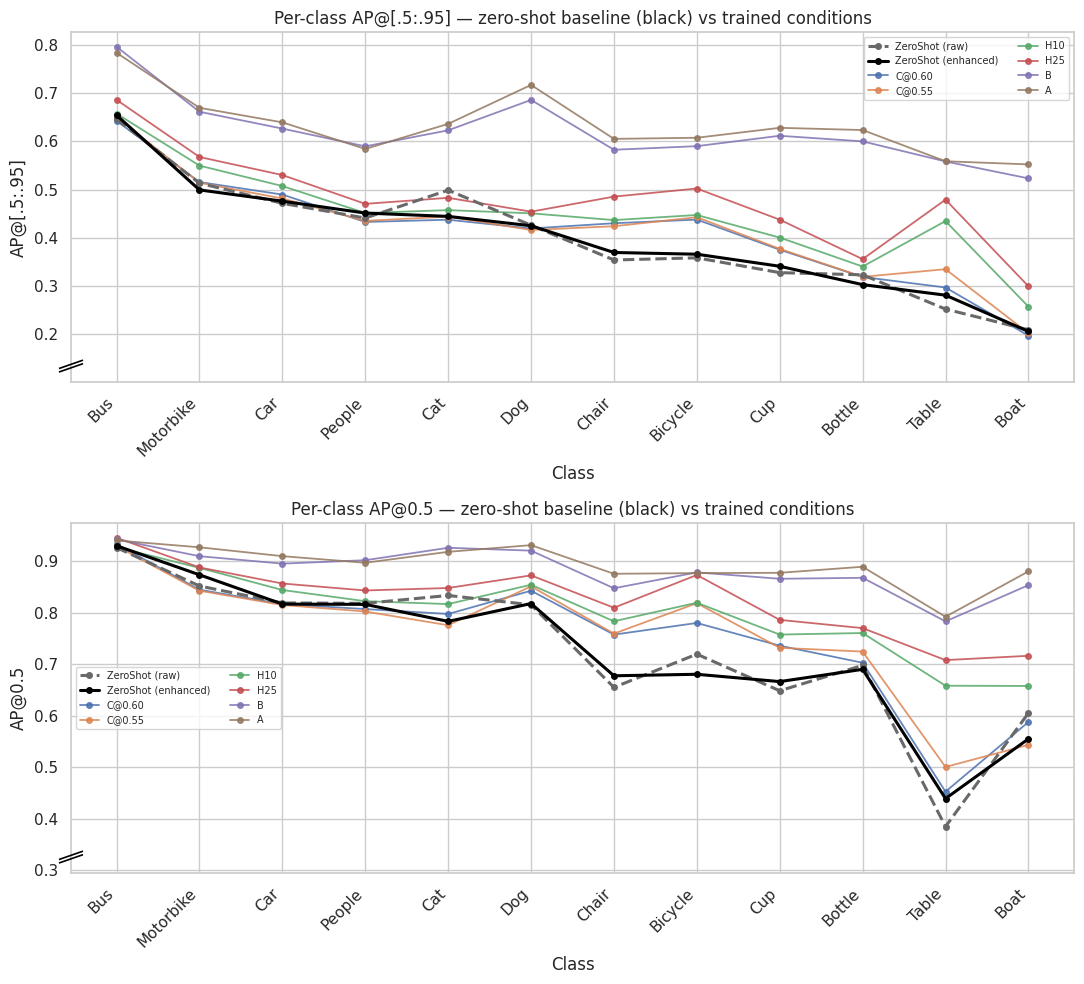


--- AP@[.5:.95]: classes gaining LEAST from training (COCO pretraining already strong) ---


,mean_gain
People,0.0444
Bus,0.0499
Cat,0.0600
Car,0.0705


--- AP@[.5:.95]: classes gaining MOST from training ---


,mean_gain
Table,0.1675
Bicycle,0.1398
Cup,0.1329
Boat,0.1321



--- AP@0.5: classes gaining LEAST from training (COCO pretraining already strong) ---


,mean_gain
Bus,0.0069
Motorbike,0.0132
People,0.0291
Car,0.0391


--- AP@0.5: classes gaining MOST from training ---


,mean_gain
Table,0.2190
Bicycle,0.1541
Boat,0.1431
Chair,0.1317


In [8]:
# Per-class results for every condition, at both IoU regimes.
# Reads the in-memory ZS / P2 / P2B objects, so nothing depends on a JSON file
# that this notebook has not written yet.

METRICS = (("AP@[.5:.95]", "per_class"), ("AP@0.5", "per_class_50"))

def collect_per_class(key):
    cols = {}
    for cond in ("raw", "enhanced"):
        m = ZS[f"ZeroShot@{cond}"]["metrics"]
        if m.get(key): cols[f"ZeroShot ({cond})"] = pd.Series(m[key])
    if P2:
        for tag in ("A", "B", "C@0.55", "C@0.60"):
            m = (P2.get("results", {}).get(tag) or {}).get("metrics")
            if m and m.get(key): cols[tag] = pd.Series(m[key])
    if P2B:
        for tag, m in (P2B.get("results") or {}).items():
            if m.get(key): cols[tag] = pd.Series(m[key])
    return pd.DataFrame(cols)

def add_gains(df):
    out = df.copy()
    for tag in [c for c in df.columns if not c.startswith("ZeroShot")]:
        floor = f"ZeroShot ({images_of(tag)})"
        if floor in df.columns:
            out[f"gain_{tag}"] = (df[tag] - df[floor]).round(4)
    return out

PC_ALL, MISSING = {}, []
for label, key in METRICS:
    df = collect_per_class(key)
    have = [c for c in df.columns]
    if df.empty or "ZeroShot (enhanced)" not in have:
        MISSING.append(label); continue
    PC_ALL[label] = df
    for tag in ("A", "B", "C@0.55", "C@0.60", "H10", "H25"):
        if tag not in have: MISSING.append(f"{label}: {tag}")

if MISSING:
    print("[warn] per-class data unavailable for:", ", ".join(MISSING))

# One class order for both panels, so they can be read against each other.
ORDER_IDX = PC_ALL["AP@[.5:.95]"].sort_values("ZeroShot (enhanced)", ascending=False).index
COL_ORDER = ["ZeroShot (raw)", "ZeroShot (enhanced)",
             "C@0.60", "C@0.55", "H10", "H25", "B", "A"]

for label in PC_ALL:
    PC_ALL[label] = add_gains(PC_ALL[label].reindex(ORDER_IDX))
    print(f"=== Per-class {label}: zero-shot vs trained ===")
    display(PC_ALL[label].round(3))

def plot_per_class(df, label, ax):
    for col in [c for c in COL_ORDER if c in df.columns]:
        zs = col.startswith("ZeroShot")
        ax.plot(df.index, df[col], marker="o", ms=4,
                lw=2.2 if zs else 1.3,
                color=("black" if col == "ZeroShot (enhanced)" else
                       "dimgrey" if zs else None),
                ls="--" if col == "ZeroShot (raw)" else "-",
                alpha=1.0 if zs else 0.85,
                zorder=3 if zs else 2, label=col)
    ax.set_ylabel(label); ax.set_xlabel("Class")
    ax.set_title(f"Per-class {label} — zero-shot baseline (black) vs trained conditions")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend(fontsize=7, ncol=2)
    pad_for_break(ax, x=False); mark_axis_break(ax)

fig, axes = plt.subplots(len(PC_ALL), 1, figsize=(11, 5 * len(PC_ALL)), squeeze=False)
for ax, (label, df) in zip(axes[:, 0], PC_ALL.items()):
    plot_per_class(df, label, ax)
plt.tight_layout(); savefig(fig, "zeroshot_per_class.png"); plt.show()

# Kept for Section 10, which persists the strict-IoU table.
PC = PC_ALL["AP@[.5:.95]"]

for label, df in PC_ALL.items():
    g = [c for c in df.columns if c.startswith("gain_")]
    if not g: continue
    mean_gain = df[g].mean(axis=1).sort_values()
    print(f"\n--- {label}: classes gaining LEAST from training "
          f"(COCO pretraining already strong) ---")
    display(mean_gain.head(4).round(4).to_frame("mean_gain"))
    print(f"--- {label}: classes gaining MOST from training ---")
    display(mean_gain.tail(4)[::-1].round(4).to_frame("mean_gain"))

## 9. Does the zero-shot model share the teacher's box style?

Phase 2 found the pseudo-label student drew boxes ~15% tighter than ExDark's convention, while
human-label runs matched it. If the untrained COCO model is *also* tight, the tightness is a property of
COCO-style annotation generally rather than something YOLO-World specifically introduced — a materially
different claim, and one that changes what the box-calibration proposal is correcting for.


In [10]:
TIGHTER_MARGIN, CONTAIN_MIN = 1.25, 0.85

def tightness(tag, dataset_dir, records):
    coco_gt = COCO(os.path.join(dataset_dir, "test", "_annotations.coco.json"))
    ann = {a["id"]: a for a in coco_gt.loadAnns(coco_gt.getAnnIds())}
    d = records[(records.kind == "detection") & records.tp
                & (records.score >= 0.50) & records.gt_id.notna()]
    n_t = n_l = 0; ratios = []
    for r in d.itertuples():
        a = ann.get(int(r.gt_id))
        if a is None: continue
        b = a["bbox"]; gb = [b[0], b[1], b[0]+b[2], b[1]+b[3]]; pb = [r.x1, r.y1, r.x2, r.y2]
        pa, ga = _area(pb), _area(gb)
        if pa <= 0 or ga <= 0: continue
        ix1, iy1 = max(pb[0], gb[0]), max(pb[1], gb[1])
        ix2, iy2 = min(pb[2], gb[2]), min(pb[3], gb[3])
        inter = max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
        ratio = ga / pa; ratios.append(ratio)
        if ratio >= TIGHTER_MARGIN and inter/pa >= CONTAIN_MIN: n_t += 1
        elif (1/ratio) >= TIGHTER_MARGIN and inter/ga >= CONTAIN_MIN: n_l += 1
    n = len(ratios)
    return {"matched": n, "%tighter": round(100*n_t/n, 1) if n else None,
            "%looser": round(100*n_l/n, 1) if n else None,
            "median_area_ratio": round(float(np.median(ratios)), 3) if n else None}

geo = {f"ZeroShot ({c})": tightness(c, DS[c], ZS[f"ZeroShot@{c}"]["records"])
       for c in ["raw", "enhanced"]}
GEO = pd.DataFrame(geo).T
if P2 and P2.get("tightness_audit"):
    ref = pd.DataFrame(P2["tightness_audit"]).set_index("Run")
    for r in ref.index:
        GEO.loc[f"{r} (phase2)"] = {"matched": ref.loc[r, "matched_dets"],
                                    "%tighter": ref.loc[r, "%tighter"],
                                    "%looser": ref.loc[r, "%looser"],
                                    "median_area_ratio": ref.loc[r, "median_area_ratio"]}
print("=== Box geometry vs ExDark annotation style ===")
display(GEO)
print("\n(%tighter high => boxes systematically smaller than ExDark GT; "
      "median_area_ratio > 1 means the same.)")


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
=== Box geometry vs ExDark annotation style ===


,matched,%tighter,%looser,median_area_ratio
ZeroShot (raw),1480.0,38.4,1.2,1.192
ZeroShot (enhanced),1530.0,36.3,2.0,1.179



(%tighter high => boxes systematically smaller than ExDark GT; median_area_ratio > 1 means the same.)


## 10. Persist & interpret


In [11]:
SUPP = {
    "run_tag": RUN_TAG,
    "protocol": {"eval_conf": EVAL_CONF, "max_detections": MAX_DETECTIONS,
                 "iou_match": IOU_MATCH, "model": "RFDETRSmall (COCO pretrained, no fine-tuning)",
                 "class_map": EXDARK_TO_COCO,
                 "note": "COCO detections outside the 12 ExDark classes are discarded, not counted as FP"},
    "zeroshot": {k: v["metrics"] for k, v in ZS.items()},
    "comparison": ALL.to_dict("records"),
    "per_class": PC.to_dict(),
    "per_class_ap50": (PC_ALL.get("AP@0.5").to_dict()
                       if "AP@0.5" in PC_ALL else None),
    "box_geometry": GEO.to_dict("index"),
}
json.dump(SUPP, open(os.path.join(RESULTS_DIR, "supplementary_zeroshot.json"), "w"),
          indent=2, default=str)
ALL.to_csv(os.path.join(RESULTS_DIR, "zeroshot_comparison.csv"), index=False)
PC.to_csv(os.path.join(RESULTS_DIR, "zeroshot_per_class.csv"))
if "AP@0.5" in PC_ALL:
    PC_ALL["AP@0.5"].to_csv(os.path.join(RESULTS_DIR, "zeroshot_per_class_ap50.csv"))
GEO.to_csv(os.path.join(RESULTS_DIR, "zeroshot_box_geometry.csv"))

print("Saved to", RESULTS_DIR)
for f in sorted(os.listdir(RESULTS_DIR)): print("  -", f)
print("\n=== Headline ===")
display(ALL[["Run", "trained", "mAP@0.5", "mAP@[.5:.95]", "adaptation_gain"]])


Saved to /content/drive/MyDrive/ExDark_dataset/supplementary_zeroshot_yoloworld_v8
  - deficit_decomposition.png
  - deficit_decomposition_C0.55.csv
  - deficit_decomposition_C0.60.csv
  - deficit_decomposition_H10.csv
  - deficit_decomposition_H25.csv
  - detections_zeroshot_enhanced.parquet
  - detections_zeroshot_raw.parquet
  - supplementary_zeroshot.json
  - zeroshot_box_geometry.csv
  - zeroshot_comparison.csv
  - zeroshot_context.png
  - zeroshot_gain.png
  - zeroshot_per_class.csv
  - zeroshot_per_class.png
  - zeroshot_per_class_ap50.csv

=== Headline ===


,Run,trained,mAP@0.5,mAP@[.5:.95],adaptation_gain
0,A,yes,0.8931,0.6339,0.2319
1,B,yes,0.8829,0.6208,0.2192
2,H25,yes,0.8267,0.4794,0.0778
3,H10,yes,0.7993,0.4494,0.0478
4,C@0.55,yes,0.7581,0.4203,0.0187
5,C@0.60,yes,0.7551,0.4164,0.0148
6,ZeroShot (raw),no,0.7315,0.4020,0.0000
7,ZeroShot (enhanced),no,0.7291,0.4016,0.0000
